# 2107541 Machine Learning for Environmental Applications
## Lecture 7 : Supervised Learning - Ensemble Learning
### Done By : 6730084521 Chatrphol Ovanonchai

## Step 1: Import the Dataset 

In [182]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [183]:
## Import Model
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.ensemble import (RandomForestRegressor , GradientBoostingRegressor)
from sklearn.metrics import (r2_score , roc_auc_score , mean_absolute_error , mean_squared_error)
from xgboost import XGBRegressor

In [184]:
## Import Dataset
df = pd.read_csv("./air_quality_regression.csv")

## Step 2: Explore the Dataset

In [185]:
df.head(5)

,PM2.5 (ug/m3),PM10 (ug/m3),NO2 (ug/m3),CO (mg/m3),O3 (ug/m3),Temperature (C),Humidity (%),Wind Speed (m/s),AQI
0,59.3,83.9,31.5,0.91,64.6,17.1,61.9,4.2,131
1,142.9,207.6,46.7,1.69,69.8,12.7,71.7,4.9,290
2,111.1,165.6,39.0,1.38,55.5,27.6,42.7,5.6,221
3,91.8,127.4,25.7,1.14,94.8,20.8,36.6,1.8,186
4,27.6,71.7,15.6,0.50,85.0,32.7,51.9,2.7,57


In [186]:
# Check dataset size
df.shape

(220, 9)

In [187]:
# Check data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   PM2.5 (ug/m3)     220 non-null    float64
 1   PM10 (ug/m3)      220 non-null    float64
 2   NO2 (ug/m3)       220 non-null    float64
 3   CO (mg/m3)        220 non-null    float64
 4   O3 (ug/m3)        220 non-null    float64
 5   Temperature (C)   220 non-null    float64
 6   Humidity (%)      220 non-null    float64
 7   Wind Speed (m/s)  220 non-null    float64
 8   AQI               220 non-null    int64  
dtypes: float64(8), int64(1)
memory usage: 15.6 KB


In [188]:
# Check missing values
df.isnull().sum()

PM2.5 (ug/m3)       0
PM10 (ug/m3)        0
NO2 (ug/m3)         0
CO (mg/m3)          0
O3 (ug/m3)          0
Temperature (C)     0
Humidity (%)        0
Wind Speed (m/s)    0
AQI                 0
dtype: int64

In [189]:
# Descriptive statistics
df.describe()

,PM2.5 (ug/m3),PM10 (ug/m3),NO2 (ug/m3),CO (mg/m3),O3 (ug/m3),Temperature (C),Humidity (%),Wind Speed (m/s),AQI
count,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000,220.000000
mean,75.128182,114.367727,29.515455,1.000318,73.976818,23.871364,62.794091,3.247727,150.745455
std,43.096784,58.845559,15.415261,0.419000,12.799139,7.204105,15.492199,1.628610,83.869320
min,5.800000,10.000000,3.000000,0.280000,44.800000,12.100000,35.300000,0.600000,20.000000
25%,37.950000,62.325000,17.075000,0.660000,64.900000,17.100000,49.100000,1.875000,78.750000
50%,76.700000,108.750000,27.800000,1.000000,73.000000,23.900000,64.700000,3.250000,145.500000
75%,114.775000,165.450000,41.925000,1.327500,81.750000,29.925000,74.500000,4.700000,224.000000
max,148.100000,227.000000,67.200000,1.780000,109.200000,35.900000,90.000000,6.000000,303.000000


## Step 3: Select Features and Target 

In [190]:
features = df.columns[:-1]
print(features)

X = df[features] ## feature
y = df['AQI'] ## target

Index(['PM2.5 (ug/m3)', 'PM10 (ug/m3)', 'NO2 (ug/m3)', 'CO (mg/m3)',
       'O3 (ug/m3)', 'Temperature (C)', 'Humidity (%)', 'Wind Speed (m/s)'],
      dtype='str')


## Step 4: Train/Test Split 

In [191]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state = 42)

In [192]:
print("X Training Size : " , X_train.shape)
print("X Testing Size : " , X_test.shape)

X Training Size :  (176, 8)
X Testing Size :  (44, 8)


## Step 5: Random Forest Regression (Bagging)

### Step 5.1 : Train Model (Pipeline)

In [193]:
from sklearn.pipeline import Pipeline

In [194]:
## create pipeline of regression
rf_model_pipeline = Pipeline( 
                [ ("rf_model" , RandomForestRegressor(n_estimators = 100 , random_state = 42)) ] , memory = None
)

## train model
rf_model_pipeline.fit(X_train , y_train) ## no need to names_steps

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('rf_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PM2.5 (ug/m3)','PM10 (ug/m3)','NO2 (ug/m3)',...,'Temperature (C)', 'Humidity (%)','Wind Speed (m/s)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None


In [195]:
## predict data 
y_predicted_rf = rf_model_pipeline.predict(X_test) ## predict with X_test 

### Step 5.2 : Model Evaluation

In [196]:
r2_rf = r2_score(y_test, y_predicted_rf)
mae_rf = mean_absolute_error(y_test, y_predicted_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_predicted_rf))
print("Random Forest")
print("R²:", r2_rf)
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)

Random Forest
R²: 0.8795437295093714
MAE: 17.930681818181817
RMSE: 28.109873912268558


## Step 6 : Gradient Boosting Regression (Boosting)

### Step 6.1 : Train Model (Pipeline)

In [197]:
## create pipeline of gbm
grad_boost_pipeline = Pipeline(
    [
       ("gb_model" , GradientBoostingRegressor(n_estimators = 100 , max_depth = 3 , random_state = 42 , learning_rate = 0.1) )
    ] , memory = None
)

In [198]:
## train model 
grad_boost_pipeline.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('gb_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PM2.5 (ug/m3)','PM10 (ug/m3)','NO2 (ug/m3)',...,'Temperature (C)', 'Humidity (%)','Wind Speed (m/s)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100


In [199]:
## predict data
y_predicted_gb = grad_boost_pipeline.predict(X_test)

### Step 6.2 : Model Evaluation

In [200]:
## Model Evaluation
r2_gb = r2_score(y_test, y_predicted_gb)
mae_gb = mean_absolute_error(y_test, y_predicted_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_predicted_gb))
print("Gradient Boosting")
print("R²:", r2_gb)
print("MAE:", mae_gb)
print("RMSE:", rmse_gb)

Gradient Boosting
R²: 0.8502802276493512
MAE: 18.549413461751463
RMSE: 31.338901566330456


## Step 7 : XGBoost Regression (Boosting)
> Key Idea : Try to use idea of `Boosting` & `Bagging` but it's still `Boosting`

### Step 7.1 : Train Model (Pipeline)

In [201]:
## pipeline
xg_boost_pipeline = Pipeline(
    [
       ("xg_model" , XGBRegressor(n_estimators = 100 , max_depth = 3 , random_state = 42 , learning_rate = 0.1) ) ## same hyperparameter as GBM
    ] , memory = None
)

## train data 
xg_boost_pipeline.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('xg_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[<U16](8,)","['PM2.5 (ug/m3)','PM10 (ug/m3)','NO2 (ug/m3)',...,'Temperature (C)', 'Humidity (%)','Wind Speed (m/s)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None


### Step 7.2 : Model Evaluation

In [202]:
## predict data 
y_predicted_xgb = xg_boost_pipeline.predict(X_test)

In [203]:
## evaluate
r2_xgb = r2_score(y_test, y_predicted_xgb)
mae_xgb = mean_absolute_error(y_test, y_predicted_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_predicted_xgb))
print("XGBoost")
print("R²:", r2_xgb)
print("MAE:", mae_xgb)
print("RMSE:", rmse_xgb)

XGBoost
R²: 0.8869819045066833
MAE: 16.991600036621094
RMSE: 27.228152975424628


## Step 8: Compare the Models 

In [204]:
results = pd.DataFrame({
 "Model": [
 "Random Forest",
 "Gradient Boosting",
 "XGBoost"
 ],
 "R²": [r2_rf, r2_gb, r2_xgb],
 "MAE": [mae_rf, mae_gb, mae_xgb],
 "RMSE": [rmse_rf, rmse_gb, rmse_xgb]
})
results.round(3)

,Model,R²,MAE,RMSE
0,Random Forest,0.880,17.931,28.110
1,Gradient Boosting,0.850,18.549,31.339
2,XGBoost,0.887,16.992,27.228


## Step 9: Plotting Actual vs Predicted

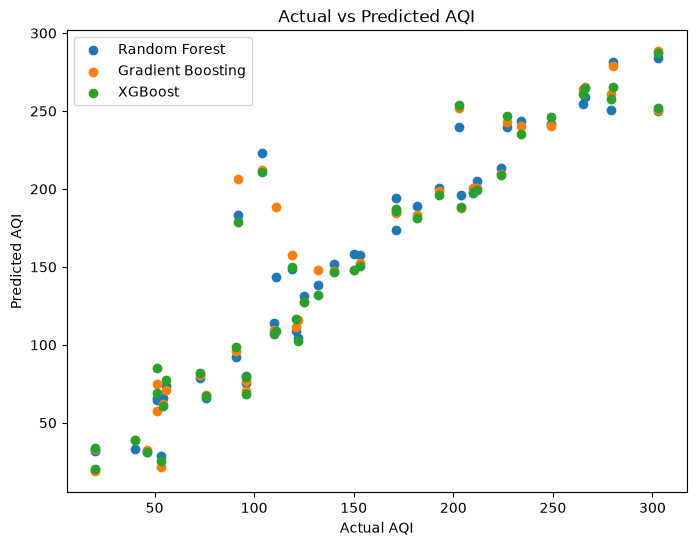

In [205]:
plt.figure(figsize=(8, 6))

## scatter plot : random forest bagging
plt.scatter(
 y_test,
 y_predicted_rf,
 label="Random Forest"
)

## scatter plot : gradient boosting 
plt.scatter(
 y_test,
 y_predicted_gb,
 label="Gradient Boosting"
)

## scatter plot : extreme gradient boosting
plt.scatter(
 y_test,
 y_predicted_xgb,
 label="XGBoost"
)
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")

plt.legend()
plt.show() ## show graph

## Step 10: Feature Importance

In [206]:
## dataframe
feature_importance_table = pd.DataFrame({
                        "Features" : features , 
                        "Random Forest": rf_model_pipeline.named_steps['rf_model'].feature_importances_ ,
                        "Gradient Boosting" : grad_boost_pipeline.named_steps['gb_model'].feature_importances_ , 
                        "XGBoost": xg_boost_pipeline.named_steps['xg_model'].feature_importances_ 
}) 

feature_importance_table.round(3)

,Features,Random Forest,Gradient Boosting,XGBoost
0,PM2.5 (ug/m3),0.782,0.787,0.606
1,PM10 (ug/m3),0.065,0.061,0.128
2,NO2 (ug/m3),0.015,0.029,0.026
3,CO (mg/m3),0.124,0.111,0.220
4,O3 (ug/m3),0.005,0.007,0.007
5,Temperature (C),0.003,0.001,0.003
6,Humidity (%),0.003,0.003,0.004
7,Wind Speed (m/s),0.003,0.001,0.007


#### My Best Model : Random Forest		
- R^2 : 0.880
- MAE : 17.931
- RMSE : 28.110

## Step 10: Feature Importance

In [207]:
rf_importance_table = pd.DataFrame({ 
                                        "Features" : features , 
                                        "Importances" : rf_model_pipeline.named_steps["rf_model"].feature_importances_ 
                                    })

rf_importance_table.sort_values(by = "Importances" , ascending = False) # descending

,Features,Importances
0,PM2.5 (ug/m3),0.782288
3,CO (mg/m3),0.124303
1,PM10 (ug/m3),0.064729
2,NO2 (ug/m3),0.015300
4,O3 (ug/m3),0.005027
5,Temperature (C),0.002951
7,Wind Speed (m/s),0.002757
6,Humidity (%),0.002643


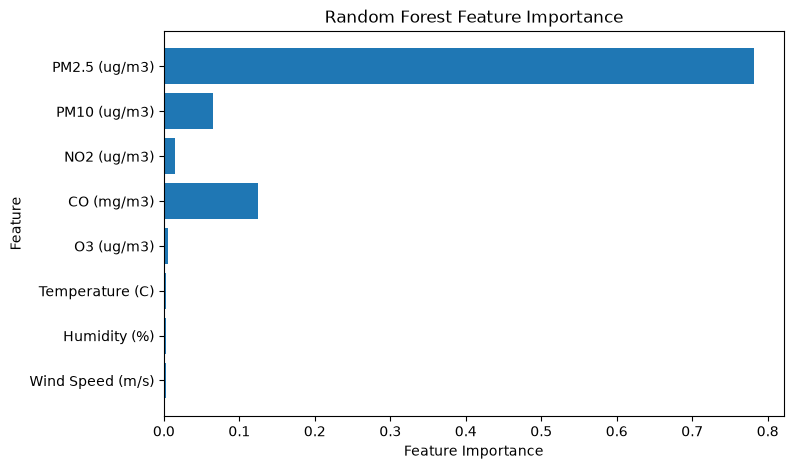

In [208]:
## plot feature importances with matplotlib 
plt.figure(figsize = (8,5)) 

## plot histogram (so using barh)
plt.barh(y = rf_importance_table['Features'],
         width = rf_importance_table['Importances']) 

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis() # flip horizontal 

plt.show()

## Step 11: Hyperparameter Tuning - Random Forest

In [209]:
## define parameter grid 
rf_param_grid = {
                    "rf_model__n_estimators": [100, 200],
                    "rf_model__max_depth": [3, 5, 10],
                    "rf_model__min_samples_leaf": [1, 2, 5]
} ## dict --> call value via __


## define grid search cv 
rf_grid_search_cv = GridSearchCV(
    estimator = rf_model_pipeline , ## can send pipeline directly
    param_grid = rf_param_grid , ## using parameter grid
    cv = 5 , # 5-Fold Validation
    scoring = "r2" ## r^2 Scoring
)

## train grid search cv (but its not model)
rf_grid_search_cv.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'rf_model__max_depth': [3, 5, ...], 'rf_model__min_samples_leaf': [1, 2, ...], 'rf_model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose ve

In [210]:
print("Best Parameters:")
print(rf_grid_search_cv.best_params_)
print("Best CV R²:")
print(rf_grid_search_cv.best_score_)

Best Parameters:
{'rf_model__max_depth': 10, 'rf_model__min_samples_leaf': 1, 'rf_model__n_estimators': 200}
Best CV R²:
0.8983231222928119


In [211]:
## predicted tuned model
y_predicted_rf_tuned = rf_grid_search_cv.predict(X_test)

r2_rf_tuned = r2_score(y_test, y_predicted_rf_tuned)
mae_rf_tuned = mean_absolute_error(y_test, y_predicted_rf_tuned)
rmse_rf_tuned = np.sqrt(mean_squared_error(y_test, y_predicted_rf_tuned))
print("Gradient Boosting (Tuned)")

print("R²:", r2_rf_tuned)
print("MAE:", mae_rf_tuned)
print("RMSE:", rmse_rf_tuned)

Gradient Boosting (Tuned)
R²: 0.8850204314397345
MAE: 17.796764524616798
RMSE: 27.46341430616263


## Step 12: Hyperparameter Tuning - Gradient Boosting

In [212]:
## define parameter grid 
gbm_param_grid = {
                    "gb_model__n_estimators": [100, 200],
                    "gb_model__max_depth": [3, 5, 7],
                    "gb_model__learning_rate": [0.05, 0.1],
                    "gb_model__min_samples_leaf": [1, 2, 5]
} ## dict --> call value via __


## define grid search cv 
gbm_grid_search_cv = GridSearchCV(
    estimator = grad_boost_pipeline , ## can send pipeline directly
    param_grid = gbm_param_grid , ## using parameter grid
    cv = 5 , # 5-Fold Validation
    scoring = "r2" ## r^2 Scoring
)

## train grid search cv (but its not model)
gbm_grid_search_cv.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'gb_model__learning_rate': [0.05, 0.1], 'gb_model__max_depth': [3, 5, ...], 'gb_model__min_samples_leaf': [1, 2, ...], 'gb_model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Suppor

In [213]:
print("Best Parameters:")
print(gbm_grid_search_cv.best_params_)
print("Best CV R²:")
print(gbm_grid_search_cv.best_score_)

Best Parameters:
{'gb_model__learning_rate': 0.05, 'gb_model__max_depth': 3, 'gb_model__min_samples_leaf': 1, 'gb_model__n_estimators': 100}
Best CV R²:
0.8939337245939383


In [214]:
## predicted tuned model
y_predicted_gb_tuned = gbm_grid_search_cv.predict(X_test)

r2_gb_tuned = r2_score(y_test, y_predicted_gb_tuned)
mae_gb_tuned = mean_absolute_error(y_test, y_predicted_gb_tuned)
rmse_gb_tuned = np.sqrt(mean_squared_error(y_test, y_predicted_gb_tuned))
print("Gradient Boosting (Tuned)")
print("R²:", r2_gb_tuned)
print("MAE:", mae_gb_tuned)
print("RMSE:", rmse_gb_tuned)

Gradient Boosting (Tuned)
R²: 0.8400146935404962
MAE: 18.976858841046297
RMSE: 32.3954666339746


## Step 13: Hyperparameter Tuning - XGBoost

In [ ]:
## define parameter grid 
xgb_param_grid = {
                    "xg_model__n_estimators": [100, 200],
                    "xg_model__max_depth": [2,3,5],
                    "xg_model__learning_rate": [0.05, 0.1] ## add new parameter "learning_rate" instead of "min_sample_leaf"
} ## dict --> call value via __


## define grid search cv 
xgb_grid_search_cv = GridSearchCV(
    estimator = xg_boost_pipeline , ## can send pipeline directly
    param_grid = xgb_param_grid , ## using parameter grid
    cv = 5 , # 5-Fold Validation
    scoring = "r2" ## r^2 Scoring
)

## train grid search cv (but its not model)
xgb_grid_search_cv.fit(X_train , y_train)

In [ ]:
print("Best Parameters:")
print(xgb_grid_search_cv.best_params_)
print("Best CV R²:")
print(xgb_grid_search_cv.best_score_)

Best Parameters:
{'xg_model__learning_rate': 0.05, 'xg_model__max_depth': 2, 'xg_model__n_estimators': 100}
Best CV R²:
0.8991919040679932


In [ ]:
## predicted tuned model
y_predicted_xgb_tuned = xgb_grid_search_cv.predict(X_test)

r2_xgb_tuned = r2_score(y_test, y_predicted_gb_tuned)
mae_xgb_tuned = mean_absolute_error(y_test, y_predicted_gb_tuned)
rmse_xgb_tuned = np.sqrt(mean_squared_error(y_test, y_predicted_gb_tuned))
print("Extreme Gradient Boosting (Tuned)")
print("R²:", r2_xgb_tuned)
print("MAE:", mae_xgb_tuned)
print("RMSE:", rmse_xgb_tuned)

Extreme Gradient Boosting (Tuned)
R²: 0.8400146935404962
MAE: 18.976858841046297
RMSE: 32.3954666339746


## Step 14: Final Model Comparison

In [ ]:
final_results = pd.DataFrame({
    
 "Model": [
 "Random Forest", "Tuned Random Forest", "Gradient Boosting", "XGBoost", "Tuned XGBoost"
 ],
 
 "R²": [
 r2_score(y_test, y_predicted_rf), r2_score(y_test, y_predicted_rf_tuned),
 r2_score(y_test, y_predicted_gb),
 r2_score(y_test, y_predicted_xgb), r2_score(y_test, y_predicted_xgb_tuned)
 ],
 
 "MAE": [
 mean_absolute_error(y_test, y_predicted_rf), mean_absolute_error(y_test, y_predicted_rf_tuned),
 mean_absolute_error(y_test, y_predicted_gb),
 mean_absolute_error(y_test, y_predicted_xgb), mean_absolute_error(y_test, y_predicted_xgb_tuned)
 ],
 
 "RMSE": [
 np.sqrt(mean_squared_error(y_test, y_predicted_rf)), np.sqrt(mean_squared_error(y_test, y_predicted_rf_tuned)),
 np.sqrt(mean_squared_error(y_test, y_predicted_gb)),
 np.sqrt(mean_squared_error(y_test, y_predicted_xgb)), np.sqrt(mean_squared_error(y_test, y_predicted_xgb_tuned))
 ]
})
final_results.round(3)

,Model,R²,MAE,RMSE
0,Random Forest,0.880,17.931,28.110
1,Tuned Random Forest,0.885,17.797,27.463
2,Gradient Boosting,0.850,18.549,31.339
3,XGBoost,0.887,16.992,27.228
4,Tuned XGBoost,0.902,16.501,25.333
